# CDC Diabetes Risk Classification with a Tabular Transformer

**Goal.** Train and evaluate a leakage-safe binary classifier on the UCI CDC Diabetes Health Indicators dataset, compare it with logistic regression, and inspect the Transformer's latent space with UMAP.

This notebook is designed to run top-to-bottom in Google Colab. It demonstrates:

- loading UCI dataset **891** with `ucimlrepo`;
- concise exploratory data analysis (EDA);
- stratified train/validation/test splitting before preprocessing;
- train-only fitting of numerical and categorical preprocessing;
- a class-balanced logistic-regression baseline;
- a small FT-Transformer-style PyTorch model built from basic components;
- early stopping, automatic CPU/GPU selection, and class-weighted loss;
- accuracy, balanced accuracy, ROC-AUC, PR-AUC, F1, classification report, confusion matrix, ROC/PR curves;
- penultimate-layer embeddings visualized with UMAP.

> **Target definition:** UCI exposes `Diabetes_binary`: `0 = no diabetes`, `1 = prediabetes or diabetes`. This is a learning project, not a diagnostic tool. The source is survey-based and contains sensitive demographic variables; performance does not establish clinical validity or fairness.

Dataset: [UCI CDC Diabetes Health Indicators](https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators) · DOI: [10.24432/C53919](https://doi.org/10.24432/C53919)

## 1. Setup

The default quick-run setting uses a stratified 120,000-row subset so the notebook remains practical on a CPU. Set `QUICK_RUN = False` to use all 253,680 rows. On a Colab GPU, either setting is reasonable.

In [1]:
%pip install -q ucimlrepo umap-learn

In [2]:
import copy
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score,
    precision_recall_curve, roc_auc_score, roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from ucimlrepo import fetch_ucirepo
from sklearn.base import clone
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import cross_validate

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42
QUICK_RUN = False
SEED = 42
QUICK_RUN = False
QUICK_ROWS = 120_000  # Maximum sample size in quick-run mode

TEST_SIZE = 0.15
VALID_SIZE = 0.15

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__} | device: {device}")

PyTorch: 2.14.1+cu130 | device: cuda


## 2. Load the UCI data

`fetch_ucirepo(id=891)` downloads the repository's canonical 21-feature table. The code validates the expected binary target and removes identifier columns if a future package version includes one among the features.

In [3]:
uci = fetch_ucirepo(id=891)
X = uci.data.features.copy()
y_frame = uci.data.targets.copy()

if y_frame.shape[1] != 1:
    raise ValueError(f"Expected one target column, found {list(y_frame.columns)}")

target_name = y_frame.columns[0]
y = pd.to_numeric(y_frame.iloc[:, 0], errors="raise").astype(int)

# Defensive removal of identifier-like columns; IDs must never be model inputs.
id_like = [c for c in X.columns if c.lower() in {"id", "index", "patient_id"}]
X = X.drop(columns=id_like, errors="ignore")

if sorted(y.unique().tolist()) != [0, 1]:
    raise ValueError(f"This notebook expects the binary UCI target; observed labels: {sorted(y.unique())}")

if QUICK_RUN and len(X) > QUICK_ROWS:
    keep_idx, _ = train_test_split(
        np.arange(len(X)), train_size=QUICK_ROWS, stratify=y, random_state=SEED
    )
    X = X.iloc[keep_idx].reset_index(drop=True)
    y = y.iloc[keep_idx].reset_index(drop=True)
else:
    X = X.reset_index(drop=True)
    y = y.reset_index(drop=True)

print(f"Dataset: {uci.metadata.get('name', 'CDC Diabetes Health Indicators')}")
print(f"Shape used: {X.shape} | target: {target_name}")
print("Class counts:", y.value_counts().sort_index().to_dict())
display(X.head())

Dataset: CDC Diabetes Health Indicators
Shape used: (253680, 21) | target: Diabetes_binary
Class counts: {0: 218334, 1: 35346}


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1,1,1,40,1,0,0,0,0,1,...,1,0,5,18,15,1,0,9,4,3
1,0,0,0,25,1,0,0,1,0,0,...,0,1,3,0,0,0,0,7,6,1
2,1,1,1,28,0,0,0,0,1,0,...,1,1,5,30,30,1,0,9,4,8
3,1,0,1,27,0,0,0,1,1,1,...,1,0,2,0,0,0,0,11,3,6
4,1,1,1,24,0,0,0,1,1,1,...,1,0,2,3,0,0,0,11,5,4


## 3. Concise EDA

We inspect schema, missingness, cardinality, class balance, numerical distributions, and correlations. EDA is performed before model fitting; no information from these displays is used to fit preprocessing parameters.

,dtype,missing,missing_%,unique,min,max
HighBP,int64,0,0.0,2,0,1
HighChol,int64,0,0.0,2,0,1
CholCheck,int64,0,0.0,2,0,1
BMI,int64,0,0.0,84,12,98
Smoker,int64,0,0.0,2,0,1
Stroke,int64,0,0.0,2,0,1
HeartDiseaseorAttack,int64,0,0.0,2,0,1
PhysActivity,int64,0,0.0,2,0,1
Fruits,int64,0,0.0,2,0,1
Veggies,int64,0,0.0,2,0,1


,count,mean,std,min,25%,50%,75%,max
HighBP,253680.0,0.43,0.49,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.42,0.49,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.96,0.19,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.38,6.61,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.44,0.50,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.04,0.20,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.09,0.29,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.76,0.43,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.63,0.48,0.0,0.0,1.0,1.0,1.0
Veggies,253680.0,0.81,0.39,0.0,1.0,1.0,1.0,1.0


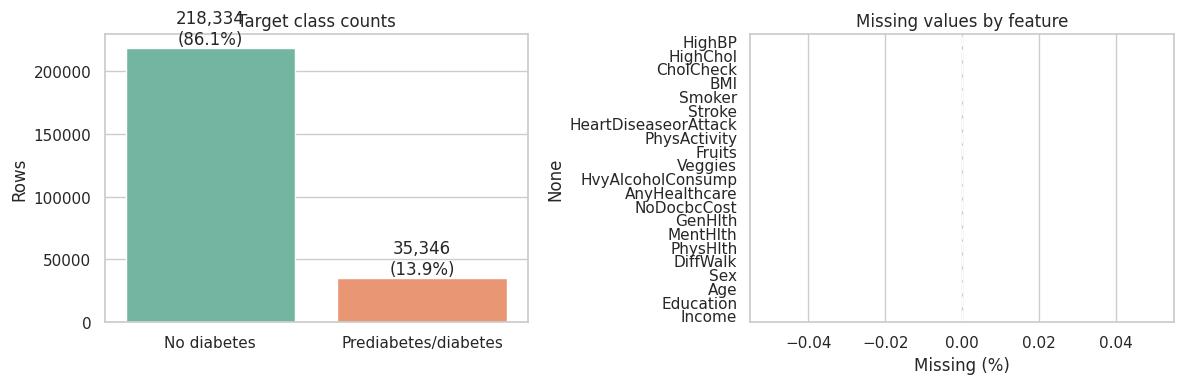

In [4]:
overview = pd.DataFrame({
    "dtype": X.dtypes.astype(str),
    "missing": X.isna().sum(),
    "missing_%": (100 * X.isna().mean()).round(3),
    "unique": X.nunique(dropna=False),
    "min": X.min(numeric_only=True),
    "max": X.max(numeric_only=True),
})
display(overview)
display(X.describe().T.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = y.value_counts().sort_index()
sns.barplot(x=["No diabetes", "Prediabetes/diabetes"], y=counts.values, ax=axes[0], palette="Set2")
axes[0].set_title("Target class counts")
axes[0].set_ylabel("Rows")
for i, value in enumerate(counts.values):
    axes[0].text(i, value, f"{value:,}\n({value / len(y):.1%})", ha="center", va="bottom")

missing_pct = 100 * X.isna().mean().sort_values(ascending=False)
sns.barplot(x=missing_pct.values, y=missing_pct.index, ax=axes[1], color="#5B8FF9")
axes[1].set_title("Missing values by feature")
axes[1].set_xlabel("Missing (%)")
plt.tight_layout()
plt.show()

Numerical (3): ['BMI', 'MentHlth', 'PhysHlth']
Categorical/ordinal (18): ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


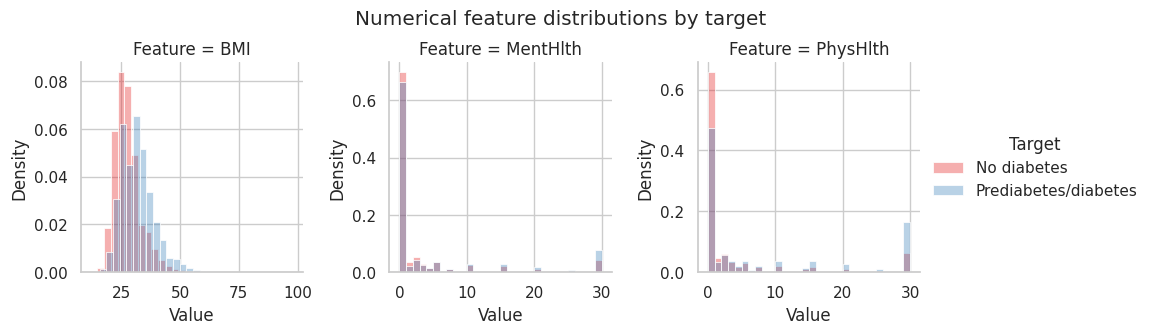

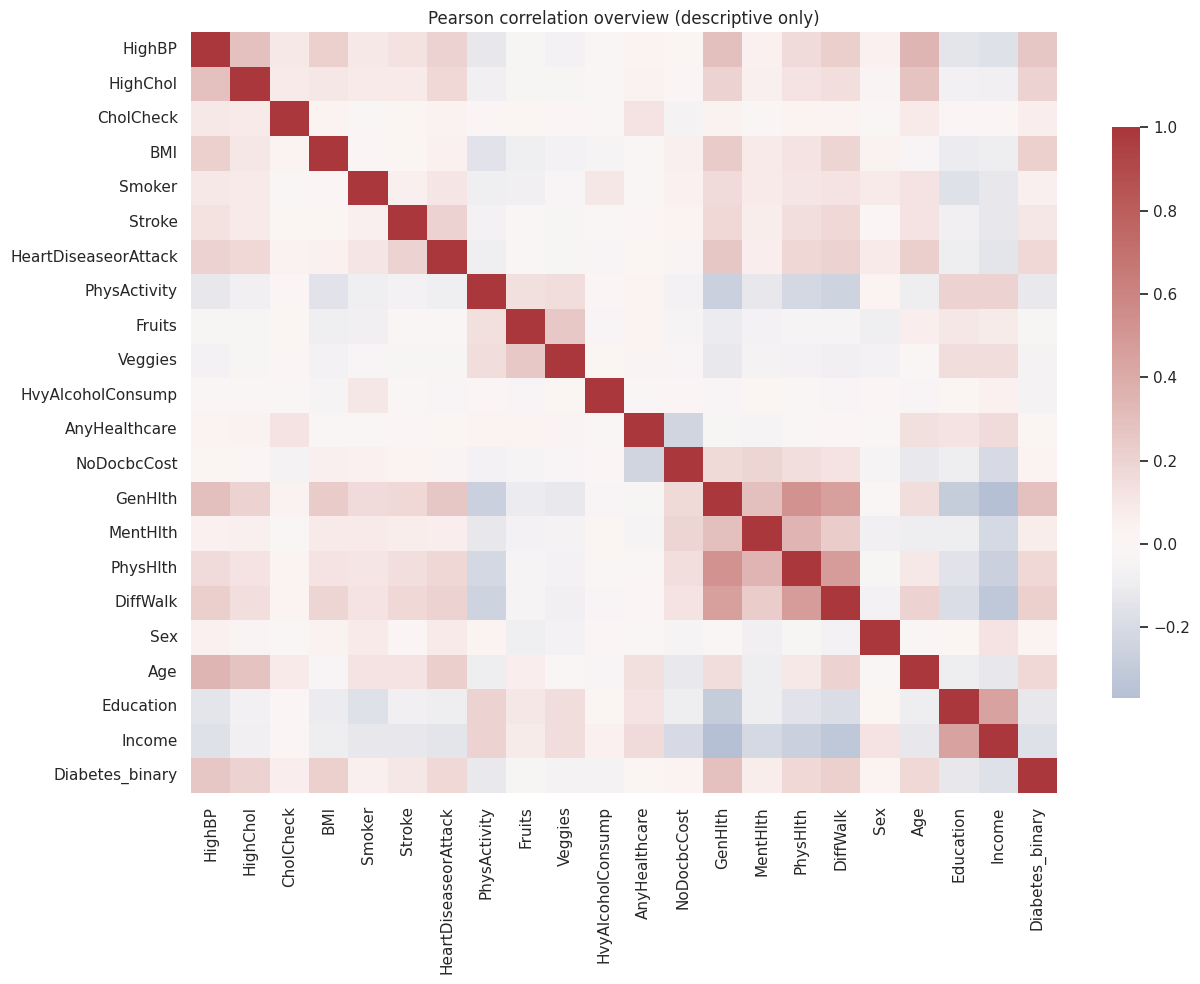

In [5]:
# Known continuous/count variables; the remaining low-cardinality fields are treated as categorical.
numerical_candidates = ["BMI", "MentHlth", "PhysHlth"]
numerical_cols = [c for c in numerical_candidates if c in X.columns]
categorical_cols = [c for c in X.columns if c not in numerical_cols]

print(f"Numerical ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical/ordinal ({len(categorical_cols)}): {categorical_cols}")

if numerical_cols:
    plot_df = X[numerical_cols].copy()
    plot_df["Target"] = y.map({0: "No diabetes", 1: "Prediabetes/diabetes"})
    long_df = plot_df.melt(id_vars="Target", var_name="Feature", value_name="Value")
    g = sns.FacetGrid(long_df, col="Feature", hue="Target", col_wrap=3, sharex=False,
                      sharey=False, height=3.2, palette="Set1")
    g.map(sns.histplot, "Value", bins=30, stat="density", common_norm=False, alpha=0.35)
    g.add_legend()
    g.fig.suptitle("Numerical feature distributions by target", y=1.04)
    plt.show()

corr_df = X.apply(pd.to_numeric, errors="coerce").copy()
corr_df[target_name] = y
plt.figure(figsize=(13, 10))
sns.heatmap(corr_df.corr(), cmap="vlag", center=0, square=False, cbar_kws={"shrink": 0.75})
plt.title("Pearson correlation overview (descriptive only)")
plt.tight_layout()
plt.show()

## 4. Leakage-safe splitting and preprocessing

We first make a stratified **70/15/15 train/validation/test split**. Imputation, scaling, category vocabularies, and class weights are then learned from the training split only.

- **Numerical inputs:** median imputation, then standardization.
- **Categorical/ordinal inputs:** string-normalized categories, train-fitted ordinal encoding, and an explicit `0` index for unseen categories.
- **Test set:** untouched until final evaluation.

In [6]:
holdout_size = TEST_SIZE + VALID_SIZE
X_train, X_hold, y_train, y_hold = train_test_split(
    X, y, test_size=holdout_size, stratify=y, random_state=SEED
)
relative_test_size = TEST_SIZE / holdout_size
X_valid, X_test, y_valid, y_test = train_test_split(
    X_hold, y_hold, test_size=relative_test_size, stratify=y_hold, random_state=SEED
)

for name, split_y in [("train", y_train), ("validation", y_valid), ("test", y_test)]:
    print(f"{name:10s}: n={len(split_y):,}, positive rate={split_y.mean():.3%}")

train     : n=177,576, positive rate=13.933%
validation: n=38,052, positive rate=13.934%
test      : n=38,052, positive rate=13.934%


## 5. Logistic-regression baseline

A linear baseline is important: a Transformer is only useful if it adds value beyond a simpler model. The baseline uses train-fitted one-hot encoding and standardization, plus `class_weight="balanced"` for target imbalance.

In [7]:
try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:  # compatibility with older scikit-learn
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=True)

baseline_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numerical_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", one_hot),
    ]), categorical_cols),
])

baseline = Pipeline([
    ("preprocess", baseline_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=400, solver="lbfgs", class_weight="balanced", random_state=SEED
    )),
])

baseline.fit(X_train, y_train)
baseline_probs = baseline.predict_proba(X_test)[:, 1]
print("Baseline fitted.")

Baseline fitted.


## 6. How attention works on a table

A table has no word order, but each **feature can be represented as a token** in a shared vector space. For a numerical feature, this notebook learns a feature-specific vector and bias and scales the vector by the standardized value. For a categorical feature, it learns an embedding table. A learned `[CLS]` token collects information across all feature tokens.

Inside self-attention, each token is projected into:

- **Query (Q):** what information this feature is looking for;
- **Key (K):** what information this feature offers;
- **Value (V):** the content passed onward.

Attention weights come from scaled query-key similarity, `softmax(QKᵀ / √d)`, and mix the value vectors. **Multi-head attention** repeats this in parallel subspaces, allowing different heads to learn different feature interactions (for example, BMI × age versus activity × general health). A **residual connection** adds each block's input back to its output, preserving information and easing optimization. **LayerNorm** stabilizes each token's representation. The position-wise **feed-forward network (FFN)** then applies a nonlinear transformation to every token. Because feature identity is already encoded by separate numerical parameters or separate categorical embedding tables, positional embeddings are not required here.

The implementation below directly uses `nn.TransformerEncoderLayer` and `nn.TransformerEncoder`, but manually constructs feature tokens, the `[CLS]` token, preprocessing, classifier head, loss, and training loop. It is intentionally compact rather than a full reproduction of every FT-Transformer design choice.

## 7. Train-only preprocessing for the Transformer

In [8]:
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
X_train_num = num_pipeline.fit_transform(X_train[numerical_cols]).astype("float32")
X_valid_num = num_pipeline.transform(X_valid[numerical_cols]).astype("float32")
X_test_num = num_pipeline.transform(X_test[numerical_cols]).astype("float32")

def normalize_categories(frame):
    return frame[categorical_cols].astype("string").fillna("__MISSING__")

cat_encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value", unknown_value=-1, dtype=np.int64
)
X_train_cat = cat_encoder.fit_transform(normalize_categories(X_train)).astype("int64") + 1
X_valid_cat = cat_encoder.transform(normalize_categories(X_valid)).astype("int64") + 1
X_test_cat = cat_encoder.transform(normalize_categories(X_test)).astype("int64") + 1
cardinalities = [len(categories) + 1 for categories in cat_encoder.categories_]

y_train_np = y_train.to_numpy(dtype="int64")
y_valid_np = y_valid.to_numpy(dtype="int64")
y_test_np = y_test.to_numpy(dtype="int64")

class_counts = np.bincount(y_train_np, minlength=2)
class_weights = len(y_train_np) / (2 * class_counts)
print("Categorical cardinalities (including unknown token):", cardinalities)
print("Training class weights:", dict(enumerate(class_weights.round(3))))

Categorical cardinalities (including unknown token): [3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 6, 3, 3, 14, 7, 9]
Training class weights: {0: np.float64(0.581), 1: np.float64(3.589)}


In [9]:
class TabularDataset(Dataset):
    def __init__(self, x_num, x_cat, y):
        self.x_num = torch.as_tensor(x_num, dtype=torch.float32)
        self.x_cat = torch.as_tensor(x_cat, dtype=torch.long)
        self.y = torch.as_tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):
        return self.x_num[index], self.x_cat[index], self.y[index]


BATCH_SIZE = 1024 if device.type == "cuda" else 512
loader_kwargs = dict(
    batch_size=BATCH_SIZE,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
)
train_loader = DataLoader(
    TabularDataset(X_train_num, X_train_cat, y_train_np),
    shuffle=True, **loader_kwargs
)
valid_loader = DataLoader(
    TabularDataset(X_valid_num, X_valid_cat, y_valid_np),
    shuffle=False, **loader_kwargs
)
test_loader = DataLoader(
    TabularDataset(X_test_num, X_test_cat, y_test_np),
    shuffle=False, **loader_kwargs
)

## 8. Simplified FT-Transformer

The output of `model.encode(...)` is the normalized `[CLS]` representation immediately before the final linear classifier. We will treat it as the model's **penultimate latent embedding**.

In [10]:
class NumericalFeatureTokenizer(nn.Module):
    # Turn each scalar numerical feature into its own learned token.
    def __init__(self, n_features, d_token):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(n_features, d_token))
        self.bias = nn.Parameter(torch.empty(n_features, d_token))
        nn.init.xavier_uniform_(self.weight)
        nn.init.zeros_(self.bias)

    def forward(self, x):
        return x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)


class TabularTransformer(nn.Module):
    def __init__(
        self, n_num, cat_cardinalities, d_token=48, n_heads=4,
        n_layers=2, ffn_dim=128, dropout=0.15, n_classes=2
    ):
        super().__init__()
        self.num_tokenizer = NumericalFeatureTokenizer(n_num, d_token)
        self.cat_embeddings = nn.ModuleList([
            nn.Embedding(cardinality, d_token, padding_idx=0)
            for cardinality in cat_cardinalities
        ])
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_token))
        nn.init.normal_(self.cls_token, std=0.02)

        layer = nn.TransformerEncoderLayer(
            d_model=d_token,
            nhead=n_heads,
            dim_feedforward=ffn_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=n_layers)
        self.final_norm = nn.LayerNorm(d_token)
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(d_token, n_classes),
        )

    def tokenize(self, x_num, x_cat):
        tokens = [self.num_tokenizer(x_num)]
        if len(self.cat_embeddings):
            cat_tokens = torch.stack(
                [embedding(x_cat[:, j]) for j, embedding in enumerate(self.cat_embeddings)],
                dim=1,
            )
            tokens.append(cat_tokens)
        feature_tokens = torch.cat(tokens, dim=1)
        cls = self.cls_token.expand(x_num.size(0), -1, -1)
        return torch.cat([cls, feature_tokens], dim=1)

    def encode(self, x_num, x_cat):
        encoded_tokens = self.encoder(self.tokenize(x_num, x_cat))
        return self.final_norm(encoded_tokens[:, 0])

    def forward(self, x_num, x_cat, return_embedding=False):
        embedding = self.encode(x_num, x_cat)
        logits = self.head(embedding)
        if return_embedding:
            return logits, embedding
        return logits


model = TabularTransformer(
    n_num=len(numerical_cols),
    cat_cardinalities=cardinalities,
    d_token=48,
    n_heads=4,
    n_layers=2,
    ffn_dim=128,
    dropout=0.15,
).to(device)

n_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"Trainable parameters: {n_parameters:,}")

# Shape smoke test before training.
batch_num, batch_cat, _ = next(iter(train_loader))
with torch.no_grad():
    smoke_logits, smoke_embedding = model(
        batch_num[:4].to(device), batch_cat[:4].to(device), return_embedding=True
    )
print("Smoke-test shapes:", smoke_logits.shape, smoke_embedding.shape)

/tmp/ipykernel_578/3416761387.py:37: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(layer, num_layers=n_layers)


TabularTransformer(
  (num_tokenizer): NumericalFeatureTokenizer()
  (cat_embeddings): ModuleList(
    (0-11): 12 x Embedding(3, 48, padding_idx=0)
    (12): Embedding(6, 48, padding_idx=0)
    (13-14): 2 x Embedding(3, 48, padding_idx=0)
    (15): Embedding(14, 48, padding_idx=0)
    (16): Embedding(7, 48, padding_idx=0)
    (17): Embedding(9, 48, padding_idx=0)
  )
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=48, out_features=48, bias=True)
        )
        (linear1): Linear(in_features=48, out_features=128, bias=True)
        (dropout): Dropout(p=0.15, inplace=False)
        (linear2): Linear(in_features=128, out_features=48, bias=True)
        (norm1): LayerNorm((48,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((48,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropou

## 9. Training with early stopping

Weighted cross-entropy compensates for the minority positive class. Early stopping monitors validation loss and restores the best state. The test split is not consulted during training.

Epoch 01 | train 0.5396 | valid 0.5183 | lr 8.00e-04
Epoch 02 | train 0.5160 | valid 0.5096 | lr 8.00e-04
Epoch 03 | train 0.5126 | valid 0.5085 | lr 8.00e-04
Epoch 04 | train 0.5106 | valid 0.5108 | lr 8.00e-04
Epoch 05 | train 0.5089 | valid 0.5084 | lr 8.00e-04
Epoch 06 | train 0.5072 | valid 0.5094 | lr 8.00e-04
Epoch 07 | train 0.5070 | valid 0.5086 | lr 4.00e-04
Epoch 08 | train 0.5052 | valid 0.5085 | lr 4.00e-04
Early stopping at epoch 8; best validation loss=0.5084


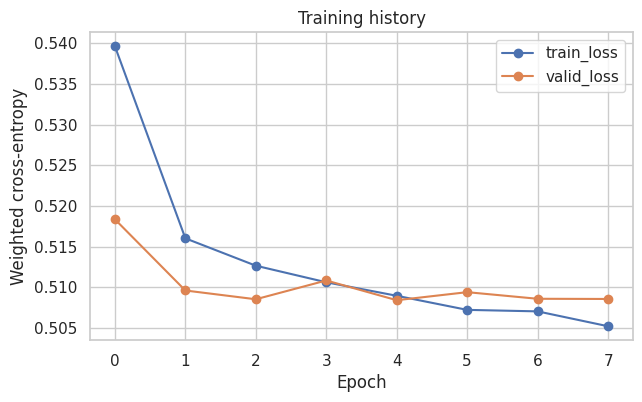

In [11]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_rows = 0.0, 0

    for x_num, x_cat, target in loader:
        x_num = x_num.to(device, non_blocking=True)
        x_cat = x_cat.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(x_num, x_cat)
            loss = criterion(logits, target)
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

        total_loss += loss.item() * len(target)
        total_rows += len(target)

    return total_loss / total_rows


def fit_with_early_stopping(model, train_loader, valid_loader, max_epochs=15, patience=3):
    criterion = nn.CrossEntropyLoss(
        weight=torch.tensor(class_weights, dtype=torch.float32, device=device)
    )
    optimizer = torch.optim.AdamW(model.parameters(), lr=8e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=1
    )

    history = {"train_loss": [], "valid_loss": []}
    best_loss = float("inf")
    best_state = None
    epochs_without_improvement = 0

    for epoch in range(1, max_epochs + 1):
        train_loss = run_epoch(model, train_loader, criterion, optimizer)
        valid_loss = run_epoch(model, valid_loader, criterion)
        scheduler.step(valid_loss)
        history["train_loss"].append(train_loss)
        history["valid_loss"].append(valid_loss)
        lr = optimizer.param_groups[0]["lr"]
        print(f"Epoch {epoch:02d} | train {train_loss:.4f} | valid {valid_loss:.4f} | lr {lr:.2e}")

        if valid_loss < best_loss - 1e-4:
            best_loss = valid_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print(f"Early stopping at epoch {epoch}; best validation loss={best_loss:.4f}")
                break

    model.load_state_dict(best_state)
    return history


history = fit_with_early_stopping(model, train_loader, valid_loader)

pd.DataFrame(history).plot(figsize=(7, 4), marker="o")
plt.title("Training history")
plt.xlabel("Epoch")
plt.ylabel("Weighted cross-entropy")
plt.show()

## 10. Test-set evaluation

The default classification threshold is 0.5. In a real screening workflow, the threshold should be selected on validation data according to clinical costs, then locked before test evaluation.

In [12]:
@torch.no_grad()
def predict_torch(model, loader, return_embeddings=False):
    model.eval()
    probabilities, labels, embeddings = [], [], []
    for x_num, x_cat, target in loader:
        x_num = x_num.to(device, non_blocking=True)
        x_cat = x_cat.to(device, non_blocking=True)
        logits, latent = model(x_num, x_cat, return_embedding=True)
        probabilities.append(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
        labels.append(target.numpy())
        if return_embeddings:
            embeddings.append(latent.cpu().numpy())
    output = (np.concatenate(labels), np.concatenate(probabilities))
    if return_embeddings:
        output += (np.concatenate(embeddings),)
    return output


def metric_row(y_true, probability, threshold=0.5):
    prediction = (probability >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, prediction),
        "balanced_accuracy": balanced_accuracy_score(y_true, prediction),
        "ROC_AUC": roc_auc_score(y_true, probability),
        "PR_AUC": average_precision_score(y_true, probability),
        "F1": f1_score(y_true, prediction),
    }


test_labels, transformer_probs, test_embeddings = predict_torch(
    model, test_loader, return_embeddings=True
)
results = pd.DataFrame({
    "Logistic regression": metric_row(y_test_np, baseline_probs),
    "Tabular Transformer": metric_row(test_labels, transformer_probs),
}).T
display(results.round(4))

transformer_predictions = (transformer_probs >= 0.5).astype(int)
print("Tabular Transformer classification report\n")
print(classification_report(
    test_labels, transformer_predictions,
    target_names=["No diabetes", "Prediabetes/diabetes"], digits=4
))

,accuracy,balanced_accuracy,ROC_AUC,PR_AUC,F1
Logistic regression,0.7305,0.7491,0.8238,0.4047,0.4448
Tabular Transformer,0.7390,0.7506,0.8283,0.4235,0.4501


Tabular Transformer classification report

                      precision    recall  f1-score   support

         No diabetes     0.9511    0.7345    0.8289     32750
Prediabetes/diabetes     0.3186    0.7667    0.4501      5302

            accuracy                         0.7390     38052
           macro avg     0.6348    0.7506    0.6395     38052
        weighted avg     0.8630    0.7390    0.7761     38052



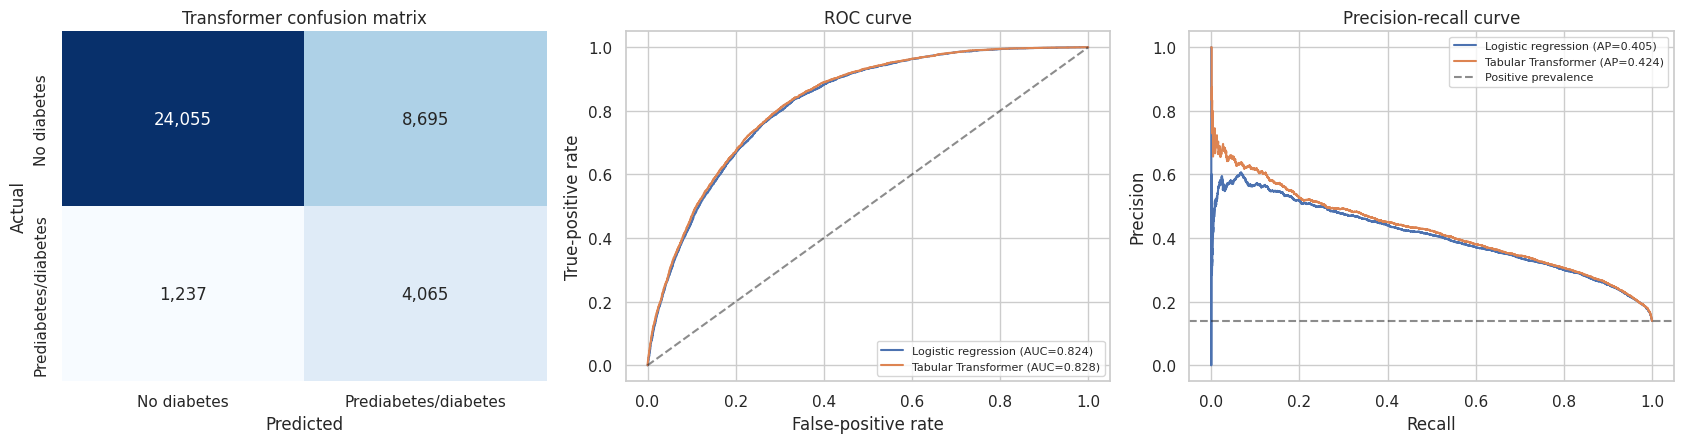

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

cm = confusion_matrix(test_labels, transformer_predictions)
sns.heatmap(
    cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0],
    xticklabels=["No diabetes", "Prediabetes/diabetes"],
    yticklabels=["No diabetes", "Prediabetes/diabetes"],
)
axes[0].set_title("Transformer confusion matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

for name, probability in [
    ("Logistic regression", baseline_probs),
    ("Tabular Transformer", transformer_probs),
]:
    fpr, tpr, _ = roc_curve(test_labels, probability)
    precision, recall, _ = precision_recall_curve(test_labels, probability)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(test_labels, probability):.3f})")
    axes[2].plot(recall, precision, label=f"{name} (AP={average_precision_score(test_labels, probability):.3f})")

axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1].set(title="ROC curve", xlabel="False-positive rate", ylabel="True-positive rate")
axes[2].axhline(test_labels.mean(), color="k", linestyle="--", alpha=0.5, label="Positive prevalence")
axes[2].set(title="Precision-recall curve", xlabel="Recall", ylabel="Precision")
axes[1].legend(fontsize=8)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 11. Penultimate latent embeddings with UMAP

UMAP is fit only for visualization. To keep it fast and readable, we draw a stratified sample of at most 6,000 test embeddings. Separation is descriptive; it is not an additional performance metric. The second panel colors the same points by predicted risk, which helps reveal smooth probability structure even when classes overlap.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


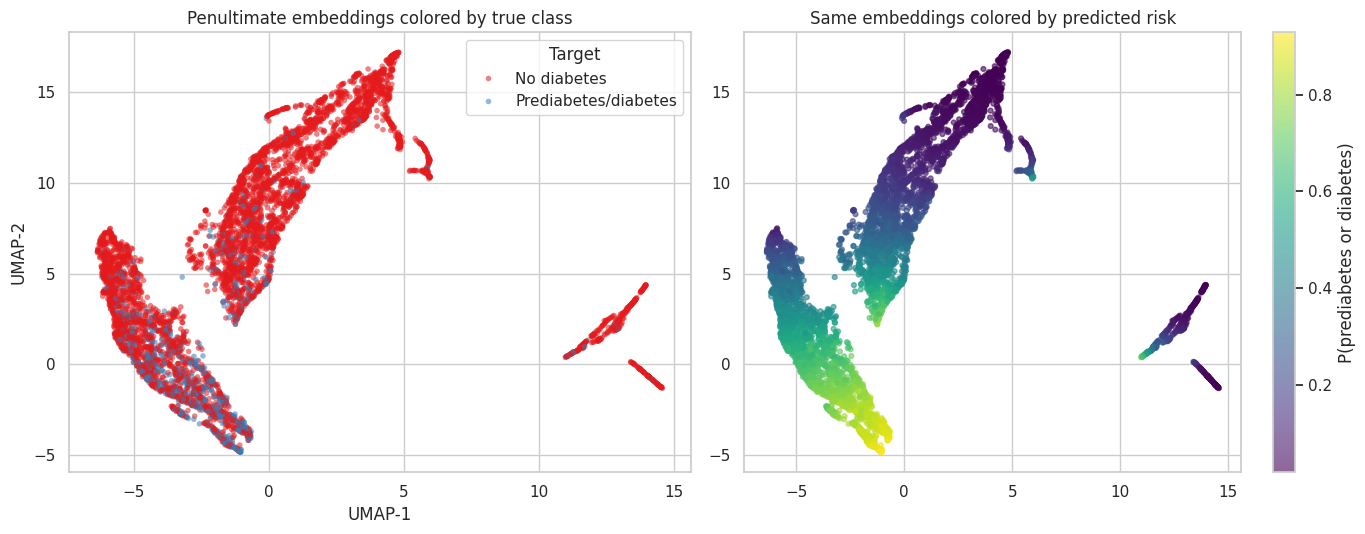

In [14]:
import umap.umap_ as umap

max_umap_rows = min(6_000, len(test_labels))
if max_umap_rows < len(test_labels):
    umap_idx, _ = train_test_split(
        np.arange(len(test_labels)), train_size=max_umap_rows,
        stratify=test_labels, random_state=SEED
    )
else:
    umap_idx = np.arange(len(test_labels))

reducer = umap.UMAP(
    n_neighbors=25, min_dist=0.15, n_components=2,
    metric="euclidean", random_state=SEED
)
embedding_2d = reducer.fit_transform(test_embeddings[umap_idx])
umap_frame = pd.DataFrame({
    "UMAP-1": embedding_2d[:, 0],
    "UMAP-2": embedding_2d[:, 1],
    "Target": pd.Series(test_labels[umap_idx]).map({0: "No diabetes", 1: "Prediabetes/diabetes"}),
    "Predicted risk": transformer_probs[umap_idx],
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(
    data=umap_frame, x="UMAP-1", y="UMAP-2", hue="Target",
    alpha=0.55, s=16, linewidth=0, palette="Set1", ax=axes[0]
)
points = axes[1].scatter(
    umap_frame["UMAP-1"], umap_frame["UMAP-2"],
    c=umap_frame["Predicted risk"], cmap="viridis", alpha=0.6, s=12
)
axes[0].set_title("Penultimate embeddings colored by true class")
axes[1].set_title("Same embeddings colored by predicted risk")
fig.colorbar(points, ax=axes[1], label="P(prediabetes or diabetes)")
plt.tight_layout()
plt.show()

## 12. Interpretation checklist and optional saving

A concise project explanation can be:

> I downloaded the UCI CDC Diabetes Health Indicators data, created stratified train/validation/test splits, and fitted all preprocessing on the training set only. I compared class-balanced logistic regression with a PyTorch tabular Transformer. I manually tokenized numerical and categorical features, passed them with a learned CLS token through multi-head self-attention encoder blocks, used early stopping and weighted cross-entropy, evaluated discrimination and thresholded performance on a held-out test set, and visualized the penultimate latent representation with UMAP.

When reporting results, mention the exact `QUICK_RUN` setting, the binary target definition, the strong class imbalance, and the fact that this observational survey dataset is not a clinical validation study.

In [15]:
# Optional: save a reproducibility bundle in the Colab runtime.
# Download these files manually if you want to keep them after the runtime ends.
import joblib

torch.save({
    "model_state_dict": model.state_dict(),
    "numerical_cols": numerical_cols,
    "categorical_cols": categorical_cols,
    "cardinalities": cardinalities,
    "model_config": {
        "d_token": 48, "n_heads": 4, "n_layers": 2,
        "ffn_dim": 128, "dropout": 0.15, "n_classes": 2,
    },
    "seed": SEED,
}, "tabular_transformer_cdc_diabetes.pt")
joblib.dump({"num_pipeline": num_pipeline, "cat_encoder": cat_encoder},
            "tabular_transformer_preprocessors.joblib")
results.to_csv("test_metrics.csv")
print("Saved model, preprocessors, and test metrics to the current runtime.")

Saved model, preprocessors, and test metrics to the current runtime.


## References

- CDC Diabetes Health Indicators, UCI Machine Learning Repository, dataset 891: https://doi.org/10.24432/C53919
- Vaswani et al. (2017), *Attention Is All You Need*: https://arxiv.org/abs/1706.03762
- Gorishniy et al. (2021), *Revisiting Deep Learning Models for Tabular Data* (FT-Transformer): https://arxiv.org/abs/2106.11959
- McInnes, Healy, and Melville (2018), *UMAP: Uniform Manifold Approximation and Projection for Dimension Reduction*: https://arxiv.org/abs/1802.03426